## Supervised Learning
## Goal: Predict avg_daily_sales using our training data

Focus on:
1. Dataset Overview 
2. identify missing columns  
3. Target Data Distribution...log transform...
(Features: population and density, median income, competitors nearby, walkability, traffic, jobs nearby, and business type.)
4. Features relationship with sales, correlations...
5. Model: Linear Regression, Decision Tree, Random Forest 
6. Compare validation Mean Absolute Error (MAE), Root Mean Squared (RMSE), R^2 
7. Test with test data set 


## Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

import matplotlib.pyplot as plt

## Data Overview
read in train / val / test parquet file

In [6]:
#Read-in train dataset
df = pd.read_parquet('../data/modeling/train_data.parquet')

In [7]:
#Convert all columns except "chain" and "bustype" to numeric to review missing values and impute missing values
string_cols = ["chain", "bustype"]  # replace with your column names

# Keep these columns as pandas strings
df[string_cols] = df[string_cols].astype("string")

# Convert all remaining columns to numeric
numeric_cols = df.columns.difference(string_cols)
df[numeric_cols] = df[numeric_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

In [ ]:
#Review missing values
summary = df.describe()

summary.loc['missing_values'] = df.isna().sum()
summary

#Export to CSV for full review
#summary.to_csv('/Users/brisabol/Documents/MADS/SIADS 696/train_missing.csv', index=True)

#Consider removing outlier(s) from average daily sales???

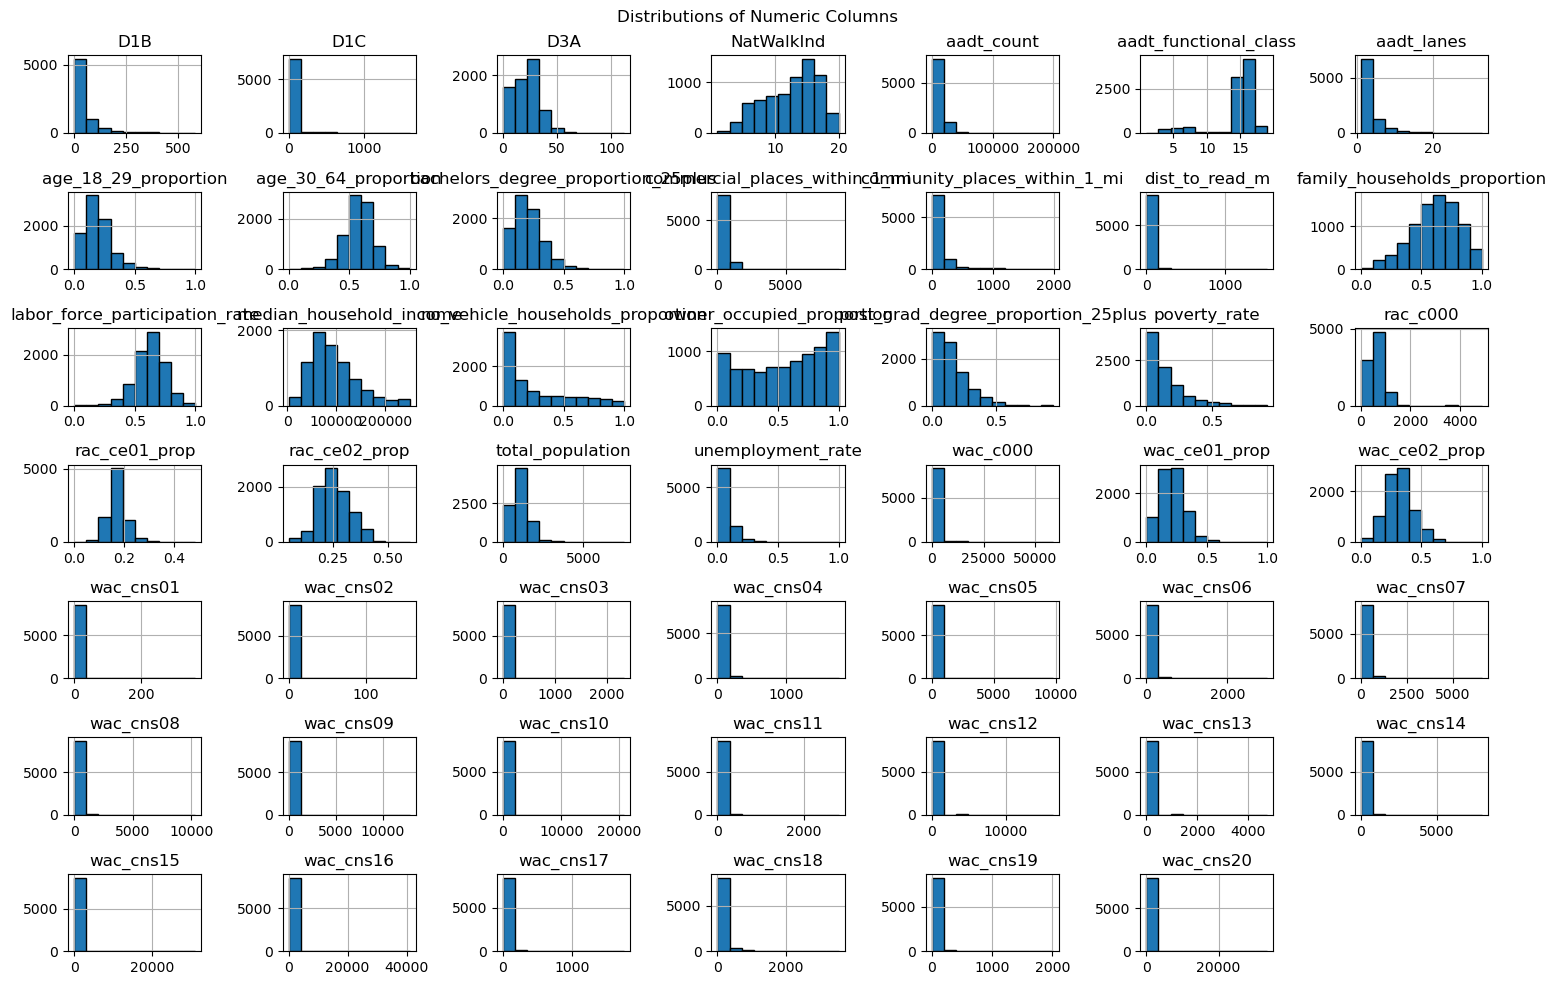

In [11]:
#Review histogram of columns to determin which method for imputation
#Ignore columns with no missing values and string type, including agtno to competitors_within_1_mi
ignore_columns = ["agtno", "avg_daily_sales", "chain", "bustype", "longitude", "latitude",
                  "bg_geoid", "tract_geoid", "competitors_within_1_mi"]
numeric_columns2 = df.columns.difference(ignore_columns)

df[numeric_columns2].hist(
    bins=10,
    figsize=(15, 10),
    edgecolor="black"
)

plt.suptitle("Distributions of Numeric Columns")
plt.tight_layout()
plt.show()

## Missing Values

In [ ]:
#Perform imputation of missing values on all columns except ignore_columns

preprocessor = ColumnTransformer(
    transformers=[
        ("mean_imputer",
         SimpleImputer(strategy="mean"),
         ["median_household_income", "age_18_29_proportion", "age_30_64_proportion", 
           "bachelors_degree_proportion_25plus", "labor_force_participation_rate", "family_households_proportion",
           "owner_occupied_proportion", "D3A", "NatWalkInd", "rac_ce01_prop", "rac_ce02_prop", "wac_ce01_prop", "wac_ce02_prop"]),

        ("median_imputer",
         SimpleImputer(strategy="median"),
         ["aadt_count", "aadt_functional_class", "aadt_lanes", "dist_to_read_m", "total_population",
           "poverty_rate", "post_grad_degree_proportion_25plus", "unemployment_rate",
           "no_vehicle_households_proportion", "D1B", "D1C", "commercial_places_within_1_mi", "community_places_within_1_mi",
           "rac_c000", "wac_cns01", "wac_cns02", "wac_cns03", "wac_cns04", "wac_cns05", "wac_cns06", "wac_cns07", "wac_cns08",
           "wac_cns09", "wac_cns10", "wac_cns11", "wac_cns12", "wac_cns13", "wac_cns14", "wac_cns15", "wac_cns16", "wac_cns17",
           "wac_cns18", "wac_cns19", "wac_cns20", "wac_c000"])
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

preprocessor.set_output(transform="pandas")


df_imputed = preprocessor.fit_transform(df)

df_imputed

,median_household_income,age_18_29_proportion,age_30_64_proportion,bachelors_degree_proportion_25plus,labor_force_participation_rate,family_households_proportion,owner_occupied_proportion,D3A,NatWalkInd,rac_ce01_prop,...,wac_c000,agtno,avg_daily_sales,chain,bustype,longitude,latitude,bg_geoid,tract_geoid,competitors_within_1_mi
0,137588.000000,0.201807,0.728916,0.271875,0.716867,0.467213,0.000000,27.016522,10.500000,0.094340,...,32078.0,100006,2989.605479,independent,NYC NEWSSTAND,-73.98193,40.75969,360610125001,36061012500,224.0
1,96111.000000,0.312210,0.640649,0.137688,0.787481,0.703922,0.474510,21.765083,12.541908,0.147395,...,322.0,100013,4147.939394,independent,GAS,-73.42486,40.69660,361031233044,36103123304,23.0
2,93986.047766,0.017117,0.813693,0.710994,0.664921,0.575630,0.756303,21.765083,12.541908,0.076190,...,485.0,100028,4000.453425,independent,CONV. STORE,-73.95721,40.76617,360610126014,36061012601,95.0
3,93986.047766,0.076818,0.540466,0.061693,0.527517,0.321343,0.750600,3.723396,4.666667,0.167920,...,46.0,100047,1833.794521,independent,CONV. STORE,-74.02479,42.17531,360390811011,36039081101,0.0
4,81820.000000,0.073548,0.587097,0.190798,0.427923,0.810888,0.716332,3.380415,4.666667,0.187994,...,3499.0,100048,3552.153425,independent,CONV. STORE,-74.12407,41.32219,360710139003,36071013900,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8664,85078.000000,0.438384,0.537374,0.352014,0.663768,0.275689,0.225564,27.472849,17.833333,0.174790,...,743.0,99717,2825.932877,independent,CONV. STORE,-73.99624,40.72106,360610041006,36061004100,203.0
8665,84286.000000,0.271547,0.609209,0.468305,0.926800,0.422311,0.123506,26.636415,15.666667,0.133178,...,812.0,99757,9046.871233,independent,DELI-GROCERY,-74.02671,40.62093,360470160004,36047016000,81.0
8666,66786.000000,0.256367,0.657046,0.120654,0.607810,0.592000,0.276000,17.368700,11.666667,0.265985,...,85.0,99799,1332.806849,independent,DRUG STORE,-73.99264,40.61669,360470260002,36047026000,131.0
8667,62857.000000,0.164565,0.617784,0.215573,0.604167,0.669255,0.172360,28.916170,19.666667,0.251163,...,4320.0,99866,4740.328767,independent,GROCERY STORE,-73.81502,40.76230,360811167001,36081116700,108.0


In [ ]:
#Check imputation

summary = df_imputed.describe()

summary.loc['missing_values'] = df_imputed.isna().sum()
summary

#Export to CSV for full review
#summary.to_csv('/Users/brisabol/Documents/MADS/SIADS 696/train_missing_check.csv', index=True)

In [ ]:
#Log transformation 

ignore_columns2 = ["agtno", "chain", "bustype", "longitude", "latitude", "bg_geoid", "tract_geoid"]
cols = df_imputed.columns.difference(ignore_columns2)

df_imputed[cols] = np.log1p(df_imputed[cols])

df_imputed

#Note: historgram distributions look better after log transformation


,median_household_income,age_18_29_proportion,age_30_64_proportion,bachelors_degree_proportion_25plus,labor_force_participation_rate,family_households_proportion,owner_occupied_proportion,D3A,NatWalkInd,rac_ce01_prop,...,wac_c000,agtno,avg_daily_sales,chain,bustype,longitude,latitude,bg_geoid,tract_geoid,competitors_within_1_mi
0,11.832026,0.183826,0.547494,0.240492,0.540501,0.383365,0.000000,3.332794,2.442347,0.090151,...,10.375957,100006,8.003231,independent,NYC NEWSSTAND,-73.98193,40.75969,360610125001,36061012500,5.416100
1,11.473269,0.271713,0.495092,0.128999,0.580807,0.532932,0.388326,3.125228,2.605789,0.137494,...,5.777652,100013,8.330608,independent,GAS,-73.42486,40.69660,361031233044,36103123304,3.178054
2,11.450912,0.016972,0.595365,0.537075,0.509778,0.454655,0.563211,3.125228,2.605789,0.073427,...,6.186209,100028,8.294413,independent,CONV. STORE,-73.95721,40.76617,360610126014,36061012601,4.564348
3,11.450912,0.074010,0.432085,0.059865,0.423643,0.278649,0.559958,1.552528,1.734601,0.155224,...,3.850148,100047,7.514688,independent,CONV. STORE,-74.02479,42.17531,360390811011,36039081101,0.000000
4,11.312289,0.070969,0.461906,0.174624,0.356221,0.593817,0.540190,1.477143,1.734601,0.172266,...,8.160518,100048,8.175591,independent,CONV. STORE,-74.12407,41.32219,360710139003,36071013900,1.386294
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8664,11.351336,0.363520,0.430076,0.301595,0.509085,0.243487,0.203401,3.348951,2.935628,0.161089,...,6.612041,99717,7.946948,independent,CONV. STORE,-73.99624,40.72106,360610041006,36061004100,5.318120
8665,11.341983,0.240234,0.475743,0.384109,0.655861,0.352283,0.116454,3.319134,2.813411,0.125026,...,6.700731,99757,9.110285,independent,DELI-GROCERY,-74.02671,40.62093,360470160004,36047016000,4.406719
8666,11.109264,0.228224,0.505036,0.113913,0.474873,0.464991,0.243730,2.910648,2.538974,0.235850,...,4.454347,99799,7.195792,independent,DRUG STORE,-73.99264,40.61669,360470260002,36047026000,4.882802
8667,11.048633,0.152348,0.481057,0.195216,0.472604,0.512377,0.159019,3.398399,3.028522,0.224073,...,8.371242,99866,8.464073,independent,GROCERY STORE,-73.81502,40.76230,360811167001,36081116700,4.691348


## Target Variable

target variable show original distribution and log transform view

## Features' Relationship with Sales

## Features's with Sales Correlation

## Model

## Validation

## Test